# INSTALL LIBRARIES

In [1]:
!pip install selenium beautifulsoup4 pandas lxml openpyxl matplotlib

# IMPORT LIBRARIES

In [2]:
import time, re, random, json
from urllib.parse import urlparse, parse_qs
import pandas as pd
import requests
from bs4 import BeautifulSoup
from selenium import webdriver
from selenium.webdriver.chrome.options import Options
from selenium.webdriver.common.by import By
import matplotlib.pyplot as plt

In [3]:
# Kiểm tra nhanh xem web có truy cập được bằng requests không
url = 'https://fptshop.com.vn/'
headers = {"User-Agent": "Mozilla/5.0"}

response = requests.get(url, headers=headers, timeout=15)

if response.status_code == 200:
    print("Link ngon")
    soup = BeautifulSoup(response.text, "lxml")
    print(soup.title.get_text(strip=True))
else:
    print(f"Link chớt (status {response.status_code})")

Link ngon
Fptshop.com.vn | Điện thoại, Laptop, Điện máy, Gia dụng, Phụ kiện chính hãng, giá tốt


# LINK FPT SHOP

In [4]:
TARGET = 1100          # mục tiêu dư một chút để sau khi làm sạch vẫn > 1000 dòng
MAX_PER_CAT = 350      # trần mỗi danh mục để dữ liệu không bị lệch về 1 nhóm
BASE = "https://fptshop.com.vn"

# FPT Shop không có phân trang số: mỗi danh mục dùng nút "Xem thêm N kết quả"
# (điện thoại ~141 sản phẩm), nên cào nhiều danh mục rồi gộp lại.
CATEGORIES = {
    "dien_thoai":    f"{BASE}/dien-thoai",
    "laptop":        f"{BASE}/may-tinh-xach-tay",
    "may_tinh_bang": f"{BASE}/may-tinh-bang",
    "man_hinh":      f"{BASE}/man-hinh",
    "tivi":          f"{BASE}/tivi",
    "may_giat":      f"{BASE}/may-giat",
    "tu_lanh":       f"{BASE}/tu-lanh",
    "may_lanh":      f"{BASE}/may-lanh-dieu-hoa",
    "pc":            f"{BASE}/may-tinh-de-ban",
    "phu_kien":      f"{BASE}/phu-kien",
}

In [5]:
opts = Options()
opts.add_argument("--headless=new")          # bỏ dòng này nếu muốn xem trình duyệt chạy
opts.add_argument("--window-size=1400,900")
opts.add_argument("--disable-blink-features=AutomationControlled")
opts.add_argument("user-agent=Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 "
                  "(KHTML, like Gecko) Chrome/124.0 Safari/537.36")

driver = webdriver.Chrome(options=opts)      # Selenium 4.6+ tự tải chromedriver
driver.get(CATEGORIES["dien_thoai"])
time.sleep(5)
print(driver.title)

Điện thoại, Smartphone chính hãng, giảm đến 4 triệu, góp 0%


# CHECK PAGE STRUCTURE & CONTAINERS O BACKEND

In [6]:
# FPT Shop là web Next.js, class CSS bị băm (hash) và hay đổi, nên KHÔNG dựa vào class.
# Thay vào đó nhận diện sản phẩm theo link /<danh-muc>/<slug-san-pham> + chữ giá "x.xxx.xxxđ".
PRICE_RE    = re.compile(r"\d{1,3}(?:\.\d{3})+\s*[đ₫]")
GIAM_RE     = re.compile(r"(?:Giảm|Trợ giá|Tặng)\s*(?:thêm|ngay|đến)?\s*\d[\d.,]*\s*[đ₫]", re.I)
DISCOUNT_RE = re.compile(r"-\s*(\d{1,2})\s*%")
TOTAL_RE    = re.compile(r"Tìm thấy\s*([\d.,]+)\s*kết quả")

# các link 2 đoạn path nhưng KHÔNG phải trang sản phẩm
SKIP_SEG = {"ctkm", "tin-tuc", "collection", "tim-kiem", "ho-tro", "cua-hang", "gio-hang",
            "dich-vu", "sim-so-dep", "kiem-tra-bao-hanh", "tos"}

# nút "Xem thêm 117 kết quả" (lấy phần tử sâu nhất, tránh dính nút "Xem thêm" của bộ lọc / mô tả SEO)
MORE_XPATH = ("//*[(self::button or self::a or self::div or self::span)"
              " and starts-with(normalize-space(.), 'Xem thêm')"
              " and contains(normalize-space(.), 'kết quả')"
              " and string-length(normalize-space(.)) < 40"
              " and not(.//*[starts-with(normalize-space(.), 'Xem thêm')"
              " and contains(normalize-space(.), 'kết quả')])]")

COUNT_JS = """
const SKIP = new Set(__SKIP__);
const priceRe = /\\d{1,3}(\\.\\d{3})+\\s*[đ₫]/;
const seen = new Set();
document.querySelectorAll('a[href]').forEach(a => {
  let u; try { u = new URL(a.href, location.origin); } catch (e) { return; }
  if (!u.hostname.endsWith('fptshop.com.vn')) return;
  const segs = u.pathname.split('/').filter(Boolean);
  if (segs.length !== 2 || SKIP.has(segs[0])) return;
  let n = a;
  for (let i = 0; i < 6 && n; i++, n = n.parentElement) {
    const t = n.textContent;
    if (priceRe.test(t) || t.includes('Liên hệ')) { seen.add(u.pathname); return; }
  }
});
return seen.size;
""".replace("__SKIP__", json.dumps(sorted(SKIP_SEG)))


def product_path(href):
    """'/dien-thoai/iphone-17?sku=1' -> '/dien-thoai/iphone-17'; không phải link sản phẩm -> None"""
    if not href:
        return None
    u = urlparse(href)
    if u.netloc and not u.netloc.endswith("fptshop.com.vn"):
        return None
    segs = [s for s in u.path.split("/") if s]
    if len(segs) != 2 or segs[0] in SKIP_SEG:
        return None
    return "/" + "/".join(segs)


def clean_url(href):
    sku = parse_qs(urlparse(href).query).get("sku", [None])[0]
    return BASE + product_path(href) + (f"?sku={sku}" if sku else "")


def count_cards():
    return driver.execute_script(COUNT_JS)


def total_found():
    """Đọc dòng 'Tìm thấy 141 kết quả' của danh mục (None nếu không thấy)."""
    txt = driver.execute_script("return document.body.textContent") or ""
    m = TOTAL_RE.search(re.sub(r"\s+", " ", txt))
    return int(re.sub(r"\D", "", m.group(1))) if m else None


def load_category(url, max_items, max_stuck=3):
    """Mở danh mục, bấm 'Xem thêm N kết quả' đến khi đủ max_items hoặc hết sản phẩm."""
    driver.get(url)
    time.sleep(4)
    total = total_found()
    if total:
        print(f"  trang báo có {total} kết quả")
    stuck = 0
    while stuck < max_stuck:
        n = count_cards()
        if n >= max_items:
            break
        driver.execute_script("window.scrollTo(0, document.body.scrollHeight);")
        time.sleep(1.5)
        btns = driver.find_elements(By.XPATH, MORE_XPATH)
        if btns:
            try:
                driver.execute_script("arguments[0].scrollIntoView({block:'center'}); arguments[0].click();", btns[0])
            except Exception as e:
                print("  Click lỗi:", e)
        time.sleep(random.uniform(2, 3.5))   # nghỉ để lịch sự với server
        n2 = count_cards()
        print(f"  đã load: {n2}")
        stuck = stuck + 1 if n2 == n else 0
    return driver.page_source


def find_card(a):
    """Từ thẻ <a> leo lên tới khối lớn nhất mà còn chứa đúng 1 sản phẩm."""
    node = a
    for _ in range(10):
        parent = node.parent
        if parent is None or parent.name in ("body", "html", "[document]"):
            break
        paths = {product_path(x["href"]) for x in parent.find_all("a", href=True)}
        paths.discard(None)
        if len(paths) > 1:
            break
        node = parent
    return node


def get_name(card):
    for a in card.find_all("a", href=True):          # 1) thuộc tính title của link sản phẩm
        t = (a.get("title") or "").strip()
        if t and product_path(a["href"]):
            return t
    for tag in card.find_all(["h3", "h2", "h4"]):    # 2) thẻ tiêu đề
        t = tag.get_text(" ", strip=True)
        if t:
            return t
    texts = [a.get_text(" ", strip=True) for a in card.find_all("a", href=True)]
    return max(texts, key=len) if texts else None    # 3) dự phòng: chữ dài nhất trong link


def split_prices(prices, disc):
    """Thứ tự trên web: giá gốc rồi giá sau giảm. Chỉ coi là cặp (gốc, bán) khi % giảm khớp."""
    ints = [int(re.sub(r"\D", "", p)) for p in prices[:2]]
    if len(ints) == 2 and ints[0] > ints[1]:
        real = round((1 - ints[1] / ints[0]) * 100)
        if (disc is not None and abs(real - disc) <= 2) or (disc is None and real <= 60):
            return prices[0], prices[1]
    return None, (prices[0] if prices else None)


def parse_html(html, category):
    soup = BeautifulSoup(html, "lxml")
    out, done = [], set()
    for a in soup.find_all("a", href=True):
        path = product_path(a["href"])
        if not path or path in done:
            continue
        card = find_card(a)
        text = GIAM_RE.sub(" ", card.get_text(" ", strip=True))   # bỏ "Giảm 300.000đ" để khỏi nhầm thành giá
        prices = PRICE_RE.findall(text)
        contact = "Liên hệ" in text
        if not prices and not contact:       # link menu / banner, không phải thẻ sản phẩm
            continue
        done.add(path)
        m = DISCOUNT_RE.search(text)
        disc = int(m.group(1)) if m else None
        orig, sale = split_prices(prices, disc)
        out.append({
            "category": category,
            "name": get_name(card),
            "price_sale": sale if prices else "Liên hệ",
            "price_original": orig,
            "discount": f"-{disc}%" if (disc is not None and orig) else None,
            "url": clean_url(a["href"]),
        })
    return out

In [7]:
# Chạy thử trên trang điện thoại đang mở để kiểm tra selector TRƯỚC khi cào hàng loạt
print("Tổng kết quả trang báo :", total_found())
print("Số thẻ sản phẩm (JS)   :", count_cards())
print("Số nút 'Xem thêm' khớp  :", len(driver.find_elements(By.XPATH, MORE_XPATH)))

sample_rows = parse_html(driver.page_source, "dien_thoai")
print("Số dòng parse được     :", len(sample_rows))
for r in sample_rows[:5]:
    print(r)

Tổng kết quả trang báo : 141
Số thẻ sản phẩm (JS)   : 62
Số nút 'Xem thêm' khớp  : 1
Số dòng parse được     : 49
{'category': 'dien_thoai', 'name': 'Nubia A76 4GB (NFC)', 'price_sale': '3.090.000đ', 'price_original': '3.390.000đ', 'discount': '-9%', 'url': 'https://fptshop.com.vn/dien-thoai/nubia-a76'}
{'category': 'dien_thoai', 'name': 'Xiaomi POCO C81 Pro 4GB', 'price_sale': '3.890.000đ', 'price_original': '4.090.000đ', 'discount': '-5%', 'url': 'https://fptshop.com.vn/dien-thoai/xiaomi-poco-c81-pro'}
{'category': 'dien_thoai', 'name': 'Xiaomi Poco M8 Pro 5G 8GB', 'price_sale': '8.990.000đ', 'price_original': '10.990.000đ', 'discount': '-18%', 'url': 'https://fptshop.com.vn/dien-thoai/xiaomi-poco-m8-pro-8gb'}
{'category': 'dien_thoai', 'name': 'Honor X9d 5G 8GB', 'price_sale': '11.990.000đ', 'price_original': '12.490.000đ', 'discount': None, 'url': 'https://fptshop.com.vn/dien-thoai/honor-x9d'}
{'category': 'dien_thoai', 'name': 'Nubia V70 Design 8GB', 'price_sale': '3.890.000đ', 'pr

In [8]:
# Nếu số dòng = 0 hoặc tên/giá bị sai: in HTML của 1 thẻ để chỉnh lại get_name / split_prices
soup = BeautifulSoup(driver.page_source, "lxml")
for a in soup.find_all("a", href=True):
    if product_path(a["href"]) and PRICE_RE.search(find_card(a).get_text(" ")):
        print(str(find_card(a))[:2500])
        break

<div aria-label="1 / 5" class="swiper-slide swiper-slide-active slider-item-5 h-auto mb:mr-2 mb:w-[44.6%]" role="group" style="width: 246.4px; margin-right: -4px;"><div class="group relative flex h-full flex-col justify-between relative bg-white hover:z-1 hover:shadow h-full rounded-[10px] p-0"><div class="relative z-10 flex flex-1 flex-col"><a aria-label="Nubia A76 4GB 128GB (NFC)" class="relative flex items-center justify-between px-2" href="/dien-thoai/nubia-a76" title="Nubia A76 4GB (NFC)"><div class="flex-1 mb:flex mb:min-w-0"><div class="relative mb-2 flex h-[161px] items-center justify-center bg-[length:100%_auto] bg-top bg-no-repeat pc:h-[210px] mb:aspect-square mb:w-full mb:max-w-[120px]"><div class=""><img alt="Nubia A76 4GB (NFC)" class="transition duration-300 group-hover:scale-105 h-[120px] w-[120px] mb:h-full mb:w-full mb:object-contain" data-nimg="1" decoding="async" height="149" loading="lazy" src="https://cdn2.fptshop.com.vn/unsafe/360x0/filters:format(webp):quality(75

# CRAWL DATA

In [9]:
all_rows, seen = [], set()

for cat, url in CATEGORIES.items():
    if len(seen) >= TARGET:
        break
    need = min(MAX_PER_CAT, TARGET - len(seen))
    print(f"\n[{cat}] {url} | còn thiếu {TARGET - len(seen)} | lấy tối đa {need}")

    try:
        html = load_category(url, max_items=need + 100)   # dư một ít vì có thể trùng / lẫn link ngoài lưới
        rows = parse_html(html, cat)
    except Exception as e:
        print("  ⚠ lỗi danh mục:", e)
        continue

    if not rows:
        print("  ⚠ 0 thẻ sản phẩm: kiểm tra lại link hoặc cách parse")
        continue

    new = 0
    for r in rows:
        if new >= need:
            break
        if r["url"] and r["url"] not in seen:
            seen.add(r["url"])
            all_rows.append(r)
            new += 1
    print(f"  -> thêm {new} dòng mới | tổng url duy nhất: {len(seen)}")

    pd.DataFrame(all_rows).to_csv("fptshop_raw_checkpoint.csv", index=False, encoding="utf-8-sig")  # lưu dần, lỡ lỗi khỏi cào lại

df_raw = pd.DataFrame(all_rows)
print("\nRaw:", df_raw.shape)
df_raw["category"].value_counts()


[dien_thoai] https://fptshop.com.vn/dien-thoai | còn thiếu 1100 | lấy tối đa 350
  trang báo có 141 kết quả
  đã load: 82
  đã load: 89
  đã load: 107
  đã load: 123
  đã load: 143
  đã load: 143
  đã load: 143
  đã load: 143
  -> thêm 129 dòng mới | tổng url duy nhất: 129

[laptop] https://fptshop.com.vn/may-tinh-xach-tay | còn thiếu 971 | lấy tối đa 350
  trang báo có 366 kết quả
  đã load: 93
  đã load: 117
  đã load: 139
  đã load: 160
  đã load: 184
  đã load: 208
  đã load: 226
  đã load: 245
  đã load: 269
  đã load: 288
  đã load: 312
  đã load: 336
  đã load: 360
  đã load: 374
  đã load: 380
  đã load: 380
  đã load: 380
  đã load: 380
  -> thêm 337 dòng mới | tổng url duy nhất: 466

[may_tinh_bang] https://fptshop.com.vn/may-tinh-bang | còn thiếu 634 | lấy tối đa 350
  trang báo có 86 kết quả
  đã load: 62
  đã load: 82
  đã load: 96
  đã load: 96
  đã load: 96
  đã load: 96
  -> thêm 82 dòng mới | tổng url duy nhất: 548

[man_hinh] https://fptshop.com.vn/man-hinh | còn thi

category
laptop           337
man_hinh         157
tu_lanh          131
dien_thoai       129
may_giat          97
tivi              94
may_tinh_bang     82
may_lanh          73
Name: count, dtype: int64

In [10]:
driver.quit()

# RELOAD DATA

In [11]:
df_raw.to_csv("fptshop_raw.csv", index=False, encoding="utf-8-sig")
df_raw.tail()

,category,name,price_sale,price_original,discount,url
1095,may_lanh,Daikin Inverter 1 HP (9200 BTU) ATHF25XVMV,12.890.000đ,None,None,https://fptshop.com.vn/may-lanh-dieu-hoa/daiki...
1096,may_lanh,Daikin Inverter 1.5 HP (12300 BTU) ATHF35XVMV,14.490.000đ,16.390.000đ,-12%,https://fptshop.com.vn/may-lanh-dieu-hoa/daiki...
1097,may_lanh,Daikin Inverter 2 HP (18100 BTU) FTKF50XVMV,10.990.000đ,21.090.000đ,-48%,https://fptshop.com.vn/may-lanh-dieu-hoa/daiki...
1098,may_lanh,Xiaomi Inverter 1.5 HP ASC-12W/N1C5-VN,9.490.000đ,12.990.000đ,-27%,https://fptshop.com.vn/may-lanh-dieu-hoa/xiaom...
1099,may_lanh,LG Inverter 2 HP (17000 BTU) V18WIN1,9.990.000đ,19.890.000đ,-50%,https://fptshop.com.vn/may-lanh-dieu-hoa/lg-in...


# CLEAN DATA

In [12]:
df = pd.read_csv("fptshop_raw.csv")

def to_int(s):
    if pd.isna(s): return None
    d = re.sub(r"\D", "", str(s))
    return int(d) if d else None

# Ghi nhận "Liên hệ" trước khi chuyển sang số
df["is_contact"] = df["price_sale"].astype(str).str.contains("Liên", case=False, na=False)

for col in ["price_sale", "price_original", "discount"]:
    df[col] = df[col].apply(to_int)

df = (df.dropna(subset=["name", "url"])
        .drop_duplicates(subset="url")
        .reset_index(drop=True))

print(df.shape)
df.info()

(1100, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1100 entries, 0 to 1099
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   category        1100 non-null   object 
 1   name            1100 non-null   object 
 2   price_sale      1100 non-null   int64  
 3   price_original  959 non-null    float64
 4   discount        773 non-null    float64
 5   url             1100 non-null   object 
 6   is_contact      1100 non-null   bool   
dtypes: bool(1), float64(2), int64(1), object(3)
memory usage: 52.8+ KB


In [13]:
# Tách hãng từ tên sản phẩm (đủ dùng cho điện thoại / laptop / tivi...; phụ kiện có thể lệch)
GENERIC = re.compile(r"^(Laptop|Điện thoại|Máy tính bảng|Máy tính xách tay|Tablet|Smart Tivi|Tivi|Máy giặt|"
                     r"Tủ lạnh|Máy lạnh|Màn hình|PC Gaming|PC|Đồng hồ thông minh)\s+", re.I)
APPLE = ("iphone", "ipad", "macbook", "imac", "apple")

def get_brand(name):
    n = GENERIC.sub("", str(name)).strip()
    w = n.split()[0] if n else None
    if w and w.lower().startswith(APPLE): return "Apple"
    if w and w.lower() == "galaxy": return "Samsung"
    return w

df["brand"] = df["name"].apply(get_brand)
df.head()

,category,name,price_sale,price_original,discount,url,is_contact,brand
0,dien_thoai,Nubia A76 4GB (NFC),3090000,3390000.0,9.0,https://fptshop.com.vn/dien-thoai/nubia-a76,False,Nubia
1,dien_thoai,Xiaomi POCO C81 Pro 4GB,3890000,4090000.0,5.0,https://fptshop.com.vn/dien-thoai/xiaomi-poco-...,False,Xiaomi
2,dien_thoai,Xiaomi Poco M8 Pro 5G 8GB,8990000,10990000.0,18.0,https://fptshop.com.vn/dien-thoai/xiaomi-poco-...,False,Xiaomi
3,dien_thoai,Honor X9d 5G 8GB,11990000,12490000.0,NaN,https://fptshop.com.vn/dien-thoai/honor-x9d,False,Honor
4,dien_thoai,Nubia V70 Design 8GB,3890000,NaN,NaN,https://fptshop.com.vn/dien-thoai/nubia-v70-de...,False,Nubia


In [14]:
print("Đủ mục tiêu (> 1000 dòng):", len(df) > 1000)
print(df["category"].value_counts())
print(df.isna().sum())

df.to_csv("fptshop_clean.csv", index=False, encoding="utf-8-sig")
df.to_excel("fptshop_clean.xlsx", index=False)

Đủ mục tiêu (> 1000 dòng): True
category
laptop           337
man_hinh         157
tu_lanh          131
dien_thoai       129
may_giat          97
tivi              94
may_tinh_bang     82
may_lanh          73
Name: count, dtype: int64
category            0
name                0
price_sale          0
price_original    141
discount          327
url                 0
is_contact          0
brand               0
dtype: int64


# DATA VISUALIZATION

In [15]:
df = pd.read_csv("fptshop_clean.csv")

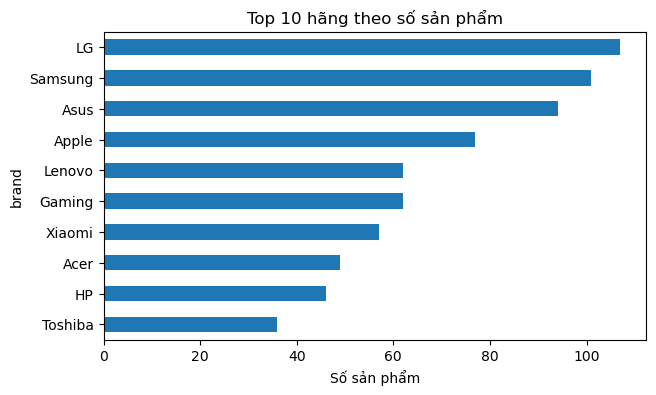

In [16]:
df["brand"].value_counts().head(10).sort_values().plot(kind="barh", figsize=(7, 4))
plt.title("Top 10 hãng theo số sản phẩm")
plt.xlabel("Số sản phẩm")
plt.show()

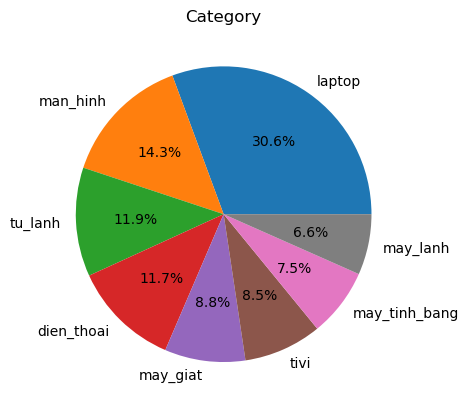

In [17]:
df["category"].value_counts().plot(kind="pie", autopct="%1.1f%%")
plt.title("Category")
plt.ylabel("")
plt.show()

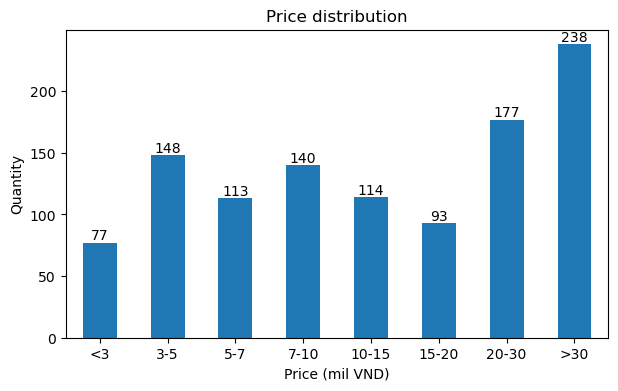

In [18]:
price = df.loc[~df["is_contact"], "price_sale"] / 1e6

bins = [0, 3, 5, 7, 10, 15, 20, 30, float("inf")]
labels = ["<3", "3-5", "5-7", "7-10", "10-15", "15-20", "20-30", ">30"]

counts = pd.cut(price, bins=bins, labels=labels).value_counts().sort_index()

ax = counts.plot(kind="bar", figsize=(7, 4))
ax.bar_label(ax.containers[0])
plt.title("Price distribution")
plt.xlabel("Price (mil VND)")
plt.ylabel("Quantity")
plt.xticks(rotation=0)
plt.show()